In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
# WEEK 5: PREDICTIVE MODELING
# Customer Sentiment Analysis of Skincare Product Reviews

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

# Week 4 output dataset
file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week4_feature_engineered_reviews.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        "Check that Cell 23 from Week 4 ran successfully."
    )

df = pd.read_csv(file_path, low_memory=False)

print("Week 4 dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nAvailable columns:")
print(df.columns.tolist())

Week 4 dataset loaded successfully!
Rows: 116137
Columns: 30

Available columns:
['unnamed_0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'review_length_chars', 'length_outlier', 'review_text_clean', 'review_word_count', 'sentence_count', 'exclamation_count', 'question_count', 'uppercase_ratio', 'rating_group', 'concern_keyword_count', 'benefit_keyword_count']


In [2]:
# STEP 3: DATA PREPARATION

required_columns = ["rating", "review_text"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}")

# Convert rating safely
df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

# Keep valid ratings and non-empty reviews
df = df.dropna(
    subset=["rating", "review_text"]
).copy()

df = df[
    df["rating"].between(1, 5)
    & df["review_text"].astype(str).str.strip().ne("")
].copy()

# Create target groups
df["satisfaction"] = pd.cut(
    df["rating"],
    bins=[0, 2, 3, 5],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# Ensure labels are valid
df = df.dropna(subset=["satisfaction"]).copy()

# Normalize text lightly; preserve punctuation and negation
df["review_text"] = (
    df["review_text"]
    .astype(str)
    .str.strip()
)

X = df["review_text"]
y = df["satisfaction"].astype(str)

print("Prepared dataset shape:", df.shape)
print("\nTarget class counts:")
display(y.value_counts().to_frame("Review Count"))

print("\nTarget class percentages:")
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Prepared dataset shape: (116137, 31)

Target class counts:


,Review Count
satisfaction,
High,95300
Low,12175
Medium,8662



Target class percentages:


,Percentage
satisfaction,
High,82.06
Low,10.48
Medium,7.46


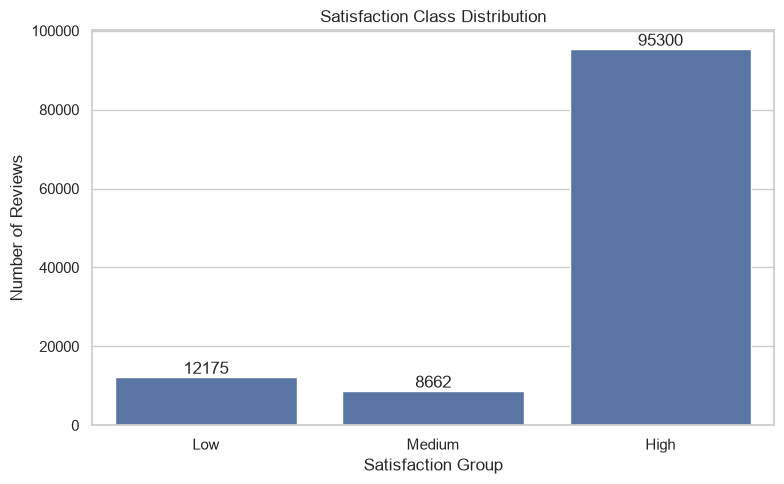

In [3]:
# STEP 4: TARGET DISTRIBUTION

class_counts = y.value_counts().reindex(
    ["Low", "Medium", "High"],
    fill_value=0
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Satisfaction Class Distribution")
plt.xlabel("Satisfaction Group")
plt.ylabel("Number of Reviews")
plt.tight_layout()

output_dir = file_path.parent
plt.savefig(
    output_dir / "week5_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
# STEP 5: TRAIN/TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining class distribution:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nTesting class distribution:")
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Training reviews: 92909
Testing reviews: 23228

Training class distribution:


,Percentage
satisfaction,
High,82.06
Low,10.48
Medium,7.46



Testing class distribution:


,Percentage
satisfaction,
High,82.06
Low,10.48
Medium,7.46


In [5]:
# STEP 6: DEFINE MODELS

models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                sublinear_tf=True
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]),

    "Linear SVC": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                sublinear_tf=True
            )
        ),
        (
            "model",
            LinearSVC(
                class_weight="balanced",
                random_state=42
            )
        )
    ]),

    "Multinomial Naive Bayes": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                sublinear_tf=True
            )
        ),
        (
            "model",
            MultinomialNB(alpha=1.0)
        )
    ])
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Majority Baseline
- Logistic Regression
- Linear SVC
- Multinomial Naive Bayes


In [ ]:
# STEP 7: TRAIN AND EVALUATE MODELS

results = []
predictions = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "Macro Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
    }

    results.append(result)

    print("Accuracy:", round(result["Accuracy"], 4))
    print("Balanced Accuracy:",
          round(result["Balanced Accuracy"], 4))
    print("Macro F1:", round(result["Macro F1"], 4))

results_df = pd.DataFrame(results).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))

results_df.to_csv(
    output_dir / "week5_model_comparison.csv",
    index=False
)

print("Model comparison saved.")


Training: Majority Baseline
Accuracy: 0.8206
Balanced Accuracy: 0.3333
Macro F1: 0.3005

Training: Logistic Regression
Accuracy: 0.8422
Balanced Accuracy: 0.7509
Macro F1: 0.6807

Training: Linear SVC


In [ ]:
# STEP 8: DETAILED CLASSIFICATION REPORT

best_model_name = results_df.iloc[0]["Model"]

print("Best model by macro-F1:", best_model_name)

best_predictions = predictions[best_model_name]

print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

In [ ]:
# STEP 9: CONFUSION MATRIX

labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Satisfaction")
plt.ylabel("Actual Satisfaction")
plt.tight_layout()

plt.savefig(
    output_dir / "week5_best_model_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# STEP 10: SAVE THE BEST MODEL AND METRICS

best_model = models[best_model_name]

joblib.dump(
    best_model,
    output_dir / "week5_best_model.joblib"
)

summary = {
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Week 5 Predictive Modeling",
    "training_reviews": int(len(X_train)),
    "testing_reviews": int(len(X_test)),
    "target_classes": ["Low", "Medium", "High"],
    "best_model_by_macro_f1": best_model_name,
    "test_metrics": {
        row["Model"]: {
            key: float(row[key])
            for key in [
                "Accuracy",
                "Balanced Accuracy",
                "Macro Precision",
                "Macro Recall",
                "Macro F1",
                "Weighted F1"
            ]
        }
        for _, row in results_df.iterrows()
    }
}

with open(
    output_dir / "week5_model_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=4)

print("Week 5 model and summary saved!")
print("Output folder:", output_dir)
print("Selected model:", best_model_name)